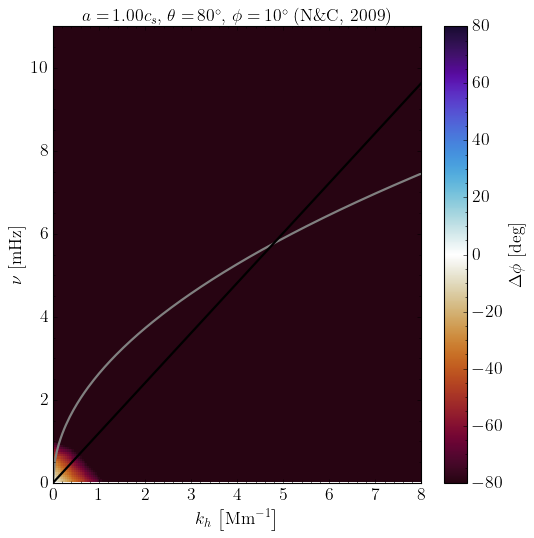

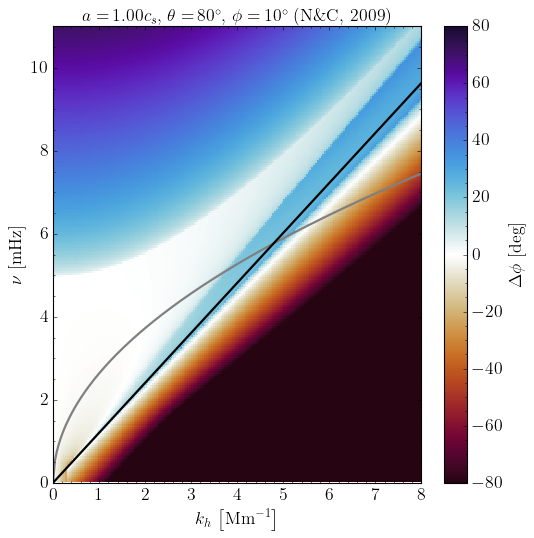

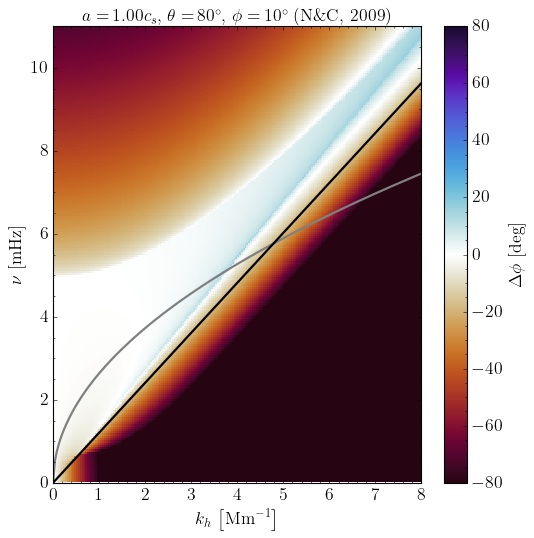

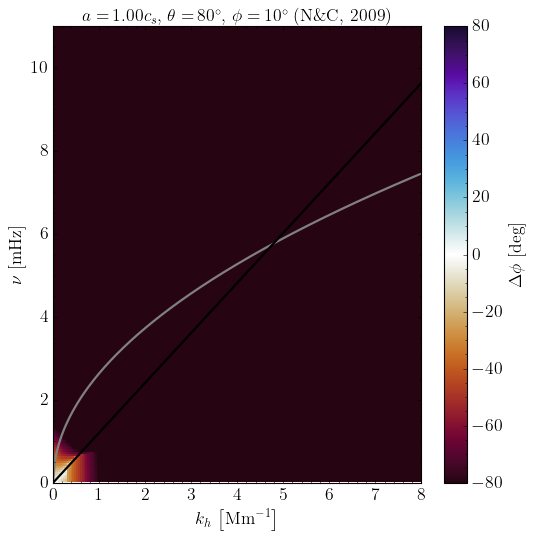

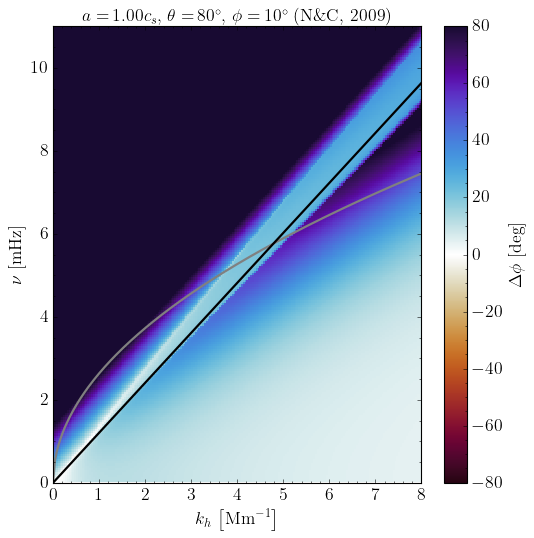

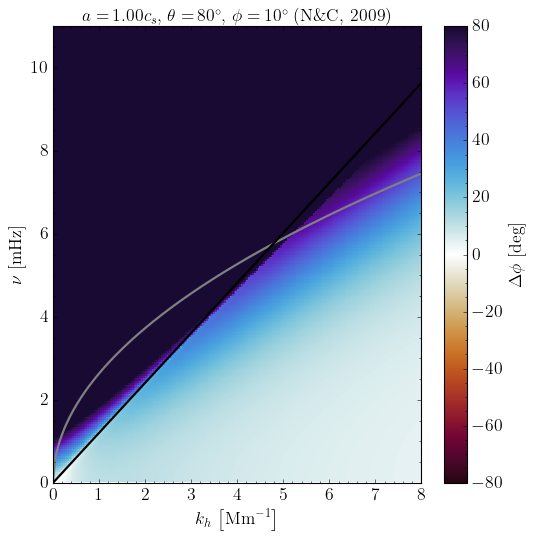

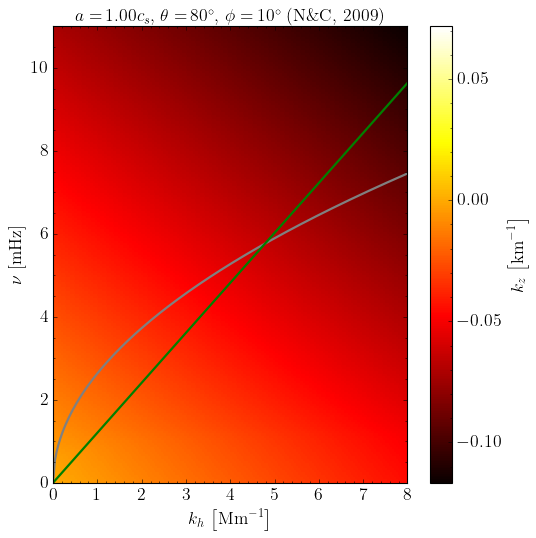

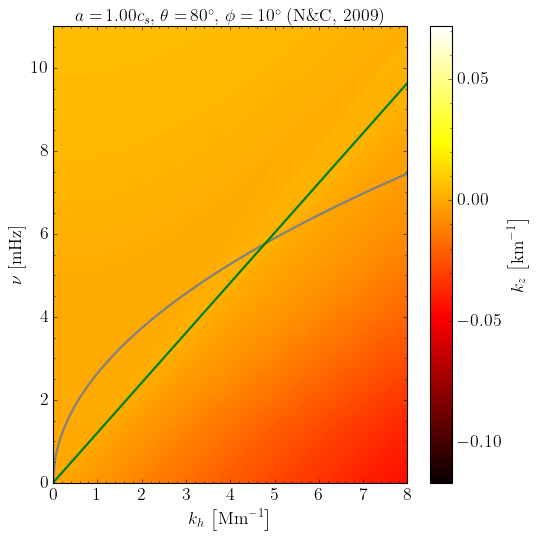

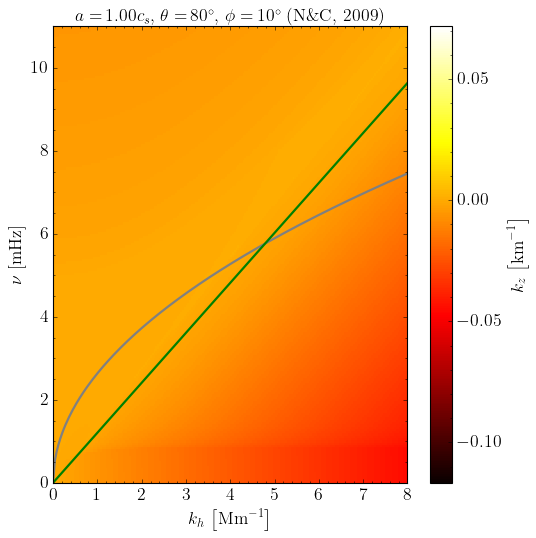

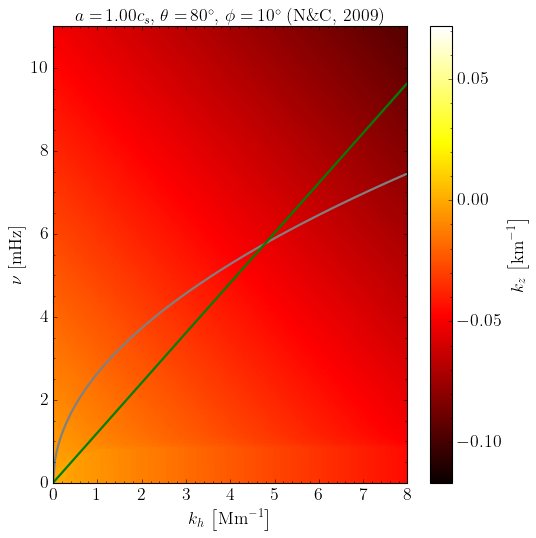

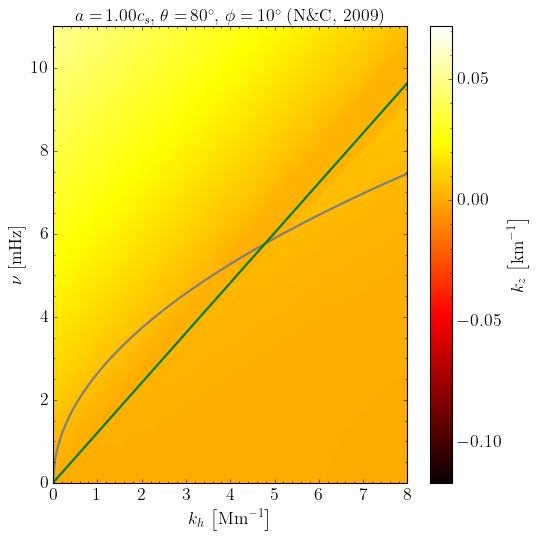

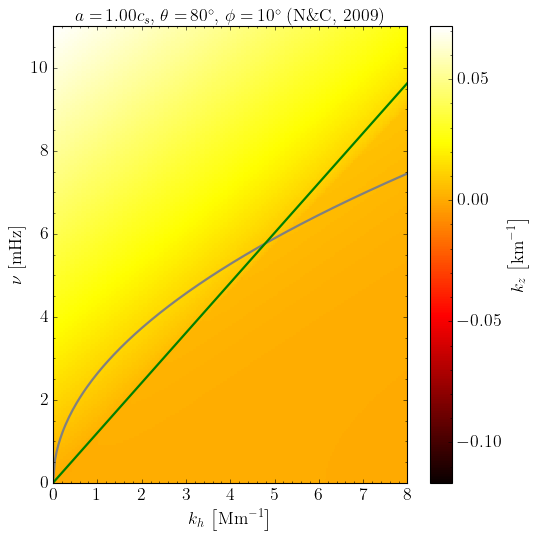

In [1]:
# Import the relevant libraries
import config as dd_config
import functions as dd_funcs
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib
import cmasher as cmr
from math import pi
from joblib import Parallel, delayed
from astropy.visualization import ZScaleInterval
from astropy.io import fits
from matplotlib import rc

# Create figure features
cmap_name = cmr.fusion
frequency_label = r'$\nu\,\left[\mathrm{mHz}\right]$'
wavenumber_label  = r'$k_{h}\,\left[\mathrm{Mm}^{-1}\right]$'
colorbar_label_kz = r'$k_{z}\,\left[\mathrm{km}^{-1}\right]$'
colorbar_label_phase = r'$\Delta\phi\,\left[\mathrm{deg}\right]$'

tex_fonts = {   "text.usetex": True,
                "font.family": "serif",
                 "font.serif": "Times New Roman",
             "axes.labelsize": 16,
                  "font.size": 16,
            "legend.fontsize": 14,
            "xtick.labelsize": 16,
            "ytick.labelsize": 16,
             "axes.titlesize": 16,
            "xtick.direction": "in",
            "ytick.direction": "in",
             "legend.frameon": True,
          "legend.framealpha": 0.8,
"axes.formatter.use_mathtext": True,
            "lines.linewidth": 2,
        "ytick.minor.visible": True,
        "xtick.minor.visible": True,
                "savefig.dpi": 300,
             "pcolor.shading": "auto",
           "figure.facecolor": "white"}

# Update matplotlib settings
plt.style.use("classic")
matplotlib.rcParams.update(tex_fonts)
rc("mathtext", **{"default": "regular"})

# Define grids
kh = np.linspace(0, 8, 200)*1e-3  # km^-1
omega = np.linspace(0, 11, 200)*2*pi*1e-3 # rad/s
kh_grid, omega_grid = np.meshgrid(kh, omega)  # km^-1, rad/s

# Intialize the diagnostic diagram
params = dd_config.params
model  = 'nc2009'  # 'nc2009', 'bunte1993', 'schunker2005'
diagram_class = dd_funcs.DiagnosticDiagram(kh_grid, omega_grid, params[model])

# Conversion factors
rad_to_mHz = (2*pi)**(-1)*1e3  # rad/s to mHz
inv_km_to_Mm = 1e3  # km^-1 to Mm^-1

# Calculate the bounds where kz^2 < 0 and calculate globally tracked kz branches.
nu = np.array(Parallel(n_jobs = -1, backend = 'loky')(delayed(diagram_class.omega_solve)(i) for i in kh))*rad_to_mHz
kz, kz_tracking = diagram_class.kz_solve_grid(return_diagnostics=True)

# Calculate grids and f-mode dispersion for plotting
kh_plot  = kh_grid*inv_km_to_Mm # Mm^-1
nu_plot  = omega_grid*rad_to_mHz  # mHz
fmode_nu = diagram_class.fmode_dispersion()*rad_to_mHz

# Calculate the corresponding phase speed and phase difference using the tracked kz branches.
v_phase = [diagram_class.phase_speed(omega_grid, kz[:, :, n]) for n in range(params[model]['kz_order'])]  # km/s
delta_phi = [diagram_class.phase_difference(omega_grid, v_phase[n], dd_config.dz) for n in range(params[model]['kz_order'])]  # rad

# Plot the diagnostic diagram
interval = ZScaleInterval()

# Plot the phase differences
for i in range(0, params[model]['kz_order']):
    phase_difference = np.real(np.nan_to_num(delta_phi[i]*180*pi**(-1), nan = 0.0, posinf=0.0, neginf=0.0)) # degrees
    if np.all(np.isclose(phase_difference, 0.0, rtol=1e-09, atol=1e-09)):
        plt.close()
        continue
    # Make the plot
    plt.figure(figsize=(7, 7))
    plt.plot(kh_plot[0], fmode_nu, 'gray')
    if (model == 'nc2009') or (model == 'bunte1993'):
        plt.plot(kh_plot[0], kh*(dd_config.ax*rad_to_mHz), color='black', linestyle='-')
    vmin, vmax = -80, 80
    plt.pcolormesh(kh_plot, nu_plot, phase_difference, cmap=cmr.fusion, shading="auto", norm=mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), rasterized=True)
    plt.colorbar(label=colorbar_label_phase)
    # for j in range(0, params[model]['omega_order']):
        # plt.plot(kh_plot[0], nu[:, j], 'k-', markersize=3)
    plt.title(f'Diagnostic Diagram for {diagram_class.model.upper()}')
    plt.xlabel(wavenumber_label)
    plt.ylabel(frequency_label)
    plt.xlim(0.0, np.max(kh_plot))
    plt.ylim(0.0, np.max(nu_plot))
    plt.tight_layout()
    plt.title(params[model]['title'])
    plt.show()

# Plot the tracked kz grids with one shared color scale. The branch-swap
# correction should leave no plot-artifact pixels to mask.
kz_plot = diagram_class.kz_plot_values(kz, component='real',diagnostics=kz_tracking)
kz_vmin, kz_vmax = diagram_class.kz_color_limits(kz, component='real', diagnostics=kz_tracking, robust=False)
kz_cmap = plt.get_cmap('hot').copy()
kz_cmap.set_bad('0.65')

for i in range(0, params[model]['kz_order']):
    kz_i = kz_plot[:, :, i]
    finite_kz_i = kz_i[np.isfinite(kz_i)]
    if finite_kz_i.size == 0 or np.all(np.isclose(finite_kz_i, 0.0, rtol=1e-09, atol=1e-09)):
        plt.close()
        continue
    # Plot the kz_grids
    plt.figure(figsize=(7, 7))
    plt.plot(kh_plot[0], fmode_nu, 'gray')
    if (model == 'nc2009') or (model == 'bunte1993'):
        plt.plot(kh_plot[0], kh*dd_config.ax*rad_to_mHz, color='green', linestyle='-')
    plt.pcolormesh(kh_plot, nu_plot, kz_i, cmap=kz_cmap, shading="auto", vmin=kz_vmin, vmax=kz_vmax, rasterized=True)
    plt.colorbar(label=colorbar_label_kz)
    plt.title(f'Tracked k_z Branch {i + 1} for {diagram_class.model.upper()}')
    plt.xlabel(wavenumber_label)
    plt.ylabel(frequency_label)
    plt.xlim(0.0, np.max(kh_plot))
    plt.ylim(0.0, np.max(nu_plot))
    plt.tight_layout()
    plt.title(params[model]['title'])
    plt.show()

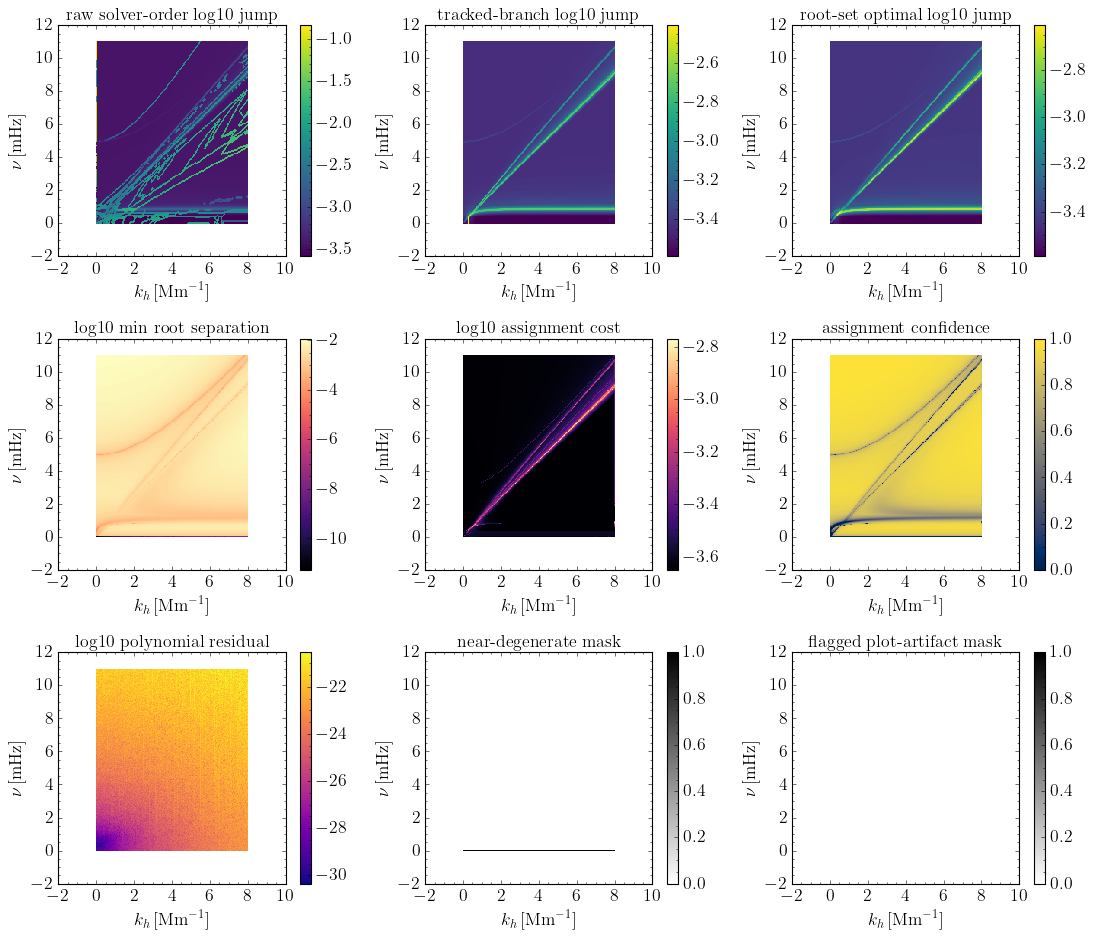

{'raw': {'mean': 0.00046637843257170685, 'median': 0.00022451998301367335, 'p95': 0.00042640519239787637, 'max': 0.14389424062558537, 'per_branch_p95': array([0.00039318, 0.00026077, 0.00079365, 0.00129367, 0.00041408,
       0.00029702])}, 'tracked': {'mean': 0.00020716559868658304, 'median': 0.0002245149213263211, 'p95': 0.00037614152018107847, 'max': 0.003911872604681131, 'per_branch_p95': array([0.00038604, 0.00036031, 0.00032188, 0.00025965, 0.00031888,
       0.00041332])}, 'p95_jump_reduction_factor': 1.1336296832973942}
Suspicious pixels: 1119
Pre-swap branch-jump excess pixels: 357
Post-swap branch-jump excess pixels: 12
Flagged plot-artifact pixels: 0
Branch-swap correction: {'enabled': True, 'iterations': 3, 'total_changed_pixels': 45614, 'ratio_threshold': 2.0, 'pre_branch_jump_excess_pixels': 357, 'post_branch_jump_excess_pixels': 12}
Nearly degenerate pixels: 200
High-residual solve pixels: 0
Worst polynomial residual: 2.8516972730291195e-21


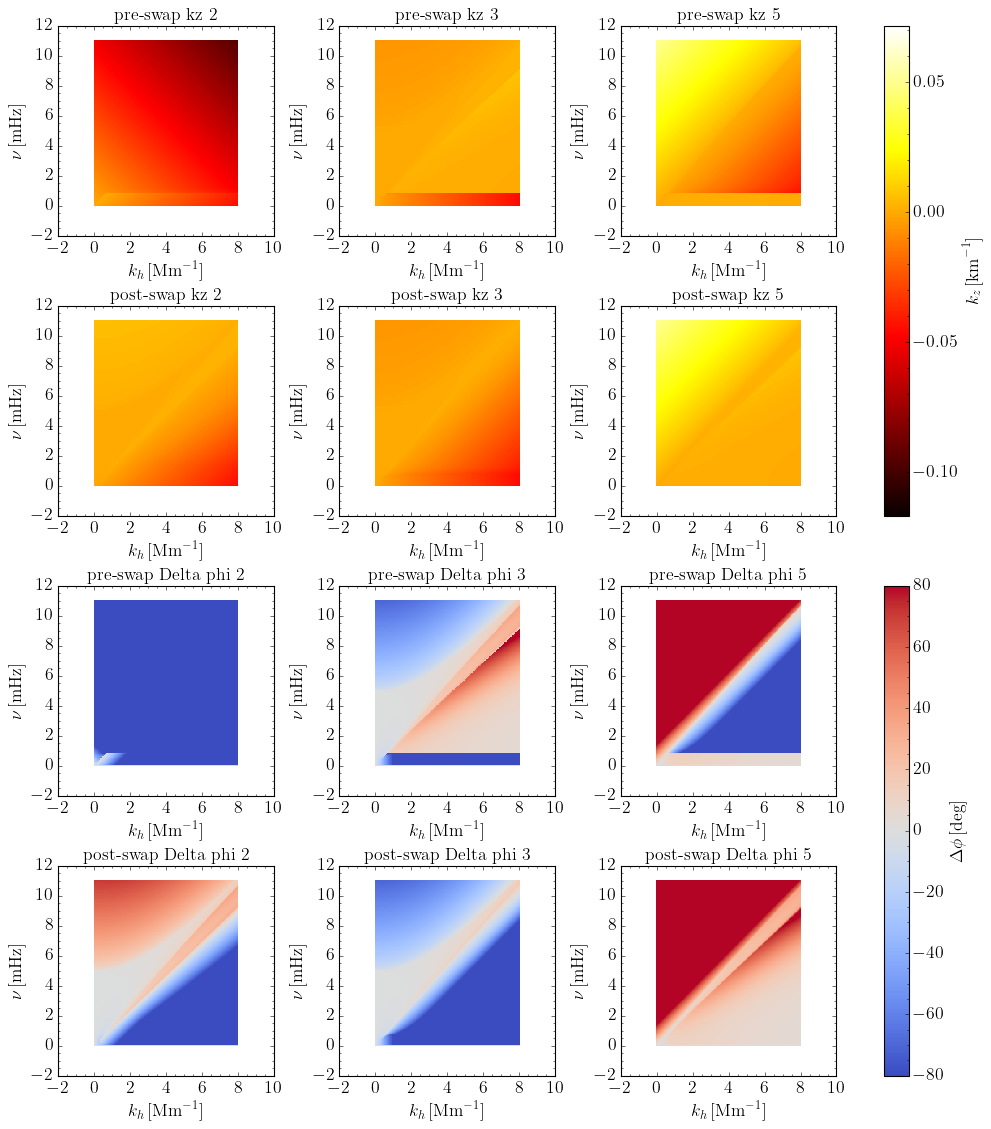

In [2]:
# Branch-tracking diagnostics: compare raw polynomial root ordering to tracked branches.
fig, axes = diagram_class.plot_kz_tracking_diagnostics(kz_tracking['raw_roots'], kz, kz_tracking)
plt.show()

print(kz_tracking['smoothness'])
print('Suspicious pixels:', np.count_nonzero(kz_tracking['uncertain_mask']))
print('Pre-swap branch-jump excess pixels:', np.count_nonzero(kz_tracking['pre_swap_branch_jump_excess_mask']))
print('Post-swap branch-jump excess pixels:', np.count_nonzero(kz_tracking['branch_jump_excess_mask']))
print('Flagged plot-artifact pixels:', np.count_nonzero(kz_tracking['plot_suspicious_mask']))
print('Branch-swap correction:', {key: value for key, value in kz_tracking['branch_swap_correction'].items() if key != 'pair_stats'})
print('Nearly degenerate pixels:', np.count_nonzero(kz_tracking['degenerate_mask']))
print('High-residual solve pixels:', np.count_nonzero(kz_tracking['solver_instability_mask']))
print('Worst polynomial residual:', np.nanmax(kz_tracking['max_root_residual']))

# Before/after maps for the branch-swap correction. Select branches or omit
# branches=... to inspect all tracked solutions.
fig, axes = diagram_class.plot_branch_swap_diagnostics(kz, kz_tracking, branches=[1, 2, 4], dz=dd_config.dz)
plt.show()

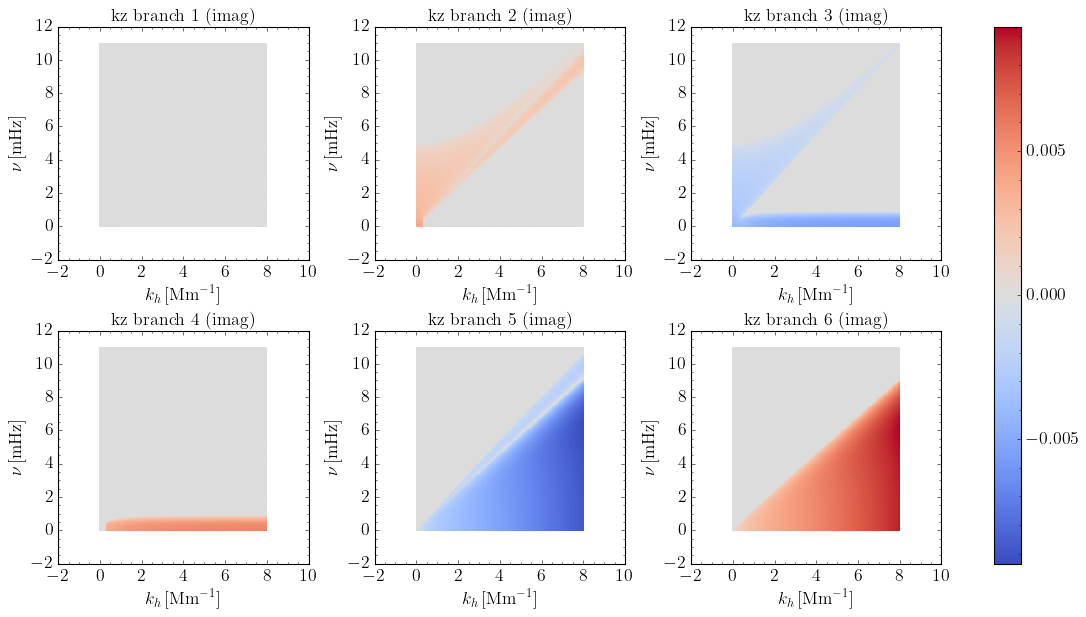

In [3]:
# Optional: inspect complex components of the tracked kz branches.
fig, axes = diagram_class.plot_kz_branches(kz, component='imag', diagnostics=kz_tracking, robust=False)
plt.show()